# Homework 3: Machine Learning for Classification

Dataset: `../../data/course_lead_scoring_2026.csv` relative to this notebook. Questions and exact requirements are in [homework.md](homework.md).

## 1. Import libraries

In [1]:
from pathlib import Path

import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from joblib import dump
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, mutual_info_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

pd.set_option('display.max_columns', None)
%matplotlib inline

## 2. Load and inspect the dataset

In [2]:
data_path = Path.cwd().parent.parent / 'data' / 'course_lead_scoring_2026.csv'
df = pd.read_csv(data_path)

print(f'Dataset: {data_path.resolve()}')
print(f'Shape: {df.shape}')
df.head()

Dataset: C:\Users\yanji\Projects\machine-learning-zoomcamp\cohorts\2026\data\course_lead_scoring_2026.csv
Shape: (5000, 9)


,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [4]:
df.info()
print('\nMissing values:')
df.isna().sum().sort_values(ascending=False)

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   lead_source               4852 non-null   str    
 1   industry                  4760 non-null   str    
 2   employment_status         4806 non-null   str    
 3   location                  4792 non-null   str    
 4   annual_income             4631 non-null   float64
 5   number_of_courses_viewed  5000 non-null   int64  
 6   interaction_count         5000 non-null   int64  
 7   lead_score                4965 non-null   float64
 8   converted                 5000 non-null   int64  
dtypes: float64(2), int64(3), str(4)
memory usage: 351.7 KB

Missing values:


annual_income               369
industry                    240
location                    208
employment_status           194
lead_source                 148
lead_score                   35
number_of_courses_viewed      0
interaction_count             0
converted                     0
dtype: int64

## 3. Prepare and split the data

Fill categorical missing values with `'NA'` and numerical missing values with `0.0`, as required. 

In [5]:
target = 'converted'
features_df = df.drop(columns=[target])
categorical_features = features_df.select_dtypes(include=['object', 'category']).columns.tolist()
numerical_features = features_df.select_dtypes(include=['number']).columns.tolist()

for feature in categorical_features:
    df[feature] = df[feature].fillna('NA')
for feature in numerical_features:
    df[feature] = df[feature].fillna(0.0)

print('Categorical features:', categorical_features)
print('Numerical features:', numerical_features)
print('Remaining missing values:', int(df.isna().sum().sum()))

Categorical features: ['lead_source', 'industry', 'employment_status', 'location']
Numerical features: ['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score']
Remaining missing values: 0


C:\Users\yanji\AppData\Local\Temp\ipykernel_60516\3990301374.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = features_df.select_dtypes(include=['object', 'category']).columns.tolist()


In [6]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=42)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=42
)

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train[target]
y_val = df_val[target]
y_test = df_test[target]
X_train = df_train.drop(columns=[target])
X_val = df_val.drop(columns=[target])
X_test = df_test.drop(columns=[target])

assert target not in X_train.columns
print(f'Train: {X_train.shape}; validation: {X_val.shape}; test: {X_test.shape}')

Train: (3000, 8); validation: (1000, 8); test: (1000, 8)


## 4. Exploratory data analysis

### Question 1

Find the most frequent value of `industry` after replacing missing categorical values with `'NA'`.

In [8]:
industry_mode = df['industry'].mode().iloc[0]
print('industry mode:', industry_mode)
df['industry'].value_counts().head()

industry mode: technology


industry
technology    1173
retail         925
healthcare     840
finance        720
education      639
Name: count, dtype: int64

**Answer: `technology`**

### Question 2

Compute correlations for all numerical features, then compare only the four candidate pairs listed in the homework.

In [9]:
correlation_matrix = df[numerical_features].corr()
correlation_matrix

,annual_income,number_of_courses_viewed,interaction_count,lead_score
annual_income,1.000000,0.161300,0.122842,0.229496
number_of_courses_viewed,0.161300,1.000000,0.721609,0.757204
interaction_count,0.122842,0.721609,1.000000,0.915746
lead_score,0.229496,0.757204,0.915746,1.000000


In [11]:
candidate_pairs = [
    ('interaction_count', 'lead_score'),
    ('number_of_courses_viewed', 'lead_score'),
    ('number_of_courses_viewed', 'interaction_count'),
    ('annual_income', 'interaction_count'),
]
pair_correlations = pd.Series(
    {f'{first} and {second}': correlation_matrix.loc[first, second]
     for first, second in candidate_pairs},
    name='correlation',
)
pair_correlations.sort_values(ascending=False)

interaction_count and lead_score                  0.915746
number_of_courses_viewed and lead_score           0.757204
number_of_courses_viewed and interaction_count    0.721609
annual_income and interaction_count               0.122842
Name: correlation, dtype: float64

**Answer: `interaction_count` and `lead_score`**

## 5. Build and train the classification model

### Question 3

Calculate mutual information between `converted` and each categorical feature using the training set only. Round scores to 2 decimals.

In [12]:
mutual_information = pd.Series(
    {
        feature: round(mutual_info_score(y_train, X_train[feature]), 2)
        for feature in categorical_features
    },
    name='mutual_information',
).sort_values(ascending=False)
mutual_information

lead_source          0.03
employment_status    0.02
industry             0.00
location             0.00
Name: mutual_information, dtype: float64

**Answer: `lead_source`** (mutual information `0.03`, rounded to 2 decimals)

### Questions 4 and 5

Train the specified logistic regression model with one-hot encoded categorical features. For Question 5, compare the baseline validation accuracy with models that omit each candidate feature.

In [14]:
def make_model(features, C=1.0):
    selected_categorical = [f for f in categorical_features if f in features]
    selected_numerical = [f for f in numerical_features if f in features]
    preprocessing = ColumnTransformer(
        transformers=[
            ('categorical', OneHotEncoder(handle_unknown='ignore'), selected_categorical),
            ('numerical', 'passthrough', selected_numerical),
        ]
    )
    classifier = LogisticRegression(
        solver='liblinear', C=C, max_iter=1000, random_state=42
    )
    return Pipeline([('preprocessing', preprocessing), ('classifier', classifier)])

feature_names = categorical_features + numerical_features
model = make_model(feature_names)
model.fit(X_train[feature_names], y_train)

baseline_accuracy = accuracy_score(y_val, model.predict(X_val[feature_names]))
print('Q4 validation accuracy:', round(baseline_accuracy, 2))

Q4 validation accuracy: 0.65


**Answer: `0.65`**

In [16]:
elimination_features = [
    'lead_source',
    'number_of_courses_viewed',
    'interaction_count',
]
feature_elimination = {}
for feature in elimination_features:
    remaining_features = [name for name in feature_names if name != feature]
    reduced_model = make_model(remaining_features)
    reduced_model.fit(X_train[remaining_features], y_train)
    reduced_accuracy = accuracy_score(
        y_val, reduced_model.predict(X_val[remaining_features])
    )
    feature_elimination[feature] = {
        'accuracy_without_feature': reduced_accuracy,
        'accuracy_difference': baseline_accuracy - reduced_accuracy,
    }

feature_elimination = pd.DataFrame(feature_elimination).T
feature_elimination.sort_values('accuracy_difference')

,accuracy_without_feature,accuracy_difference
number_of_courses_viewed,0.643,0.002
lead_source,0.642,0.003
interaction_count,0.601,0.044


**Answer: `number_of_courses_viewed`** (smallest signed accuracy difference: approximately `0.002`)

## 6. Evaluate and tune the model

### Question 6

Train the Q4 model with each listed `C`, report validation accuracy rounded to 3 decimals, and select the smallest `C` in case of a tie.

In [17]:
C_values = np.array([0.000001, 0.00001, 0.0001, 0.001])
regularization_results = []

for C in C_values:
    candidate_model = make_model(feature_names, C=C)
    candidate_model.fit(X_train[feature_names], y_train)
    validation_accuracy = accuracy_score(
        y_val, candidate_model.predict(X_val[feature_names])
    )
    regularization_results.append({
        'C': float(C),
        'validation_accuracy': validation_accuracy,
        'rounded_accuracy': round(validation_accuracy, 3),
        'model': candidate_model,
    })

regularization_table = pd.DataFrame([
    {key: result[key] for key in ('C', 'validation_accuracy', 'rounded_accuracy')}
    for result in regularization_results
])
regularization_table

,C,validation_accuracy,rounded_accuracy
0,0.000001,0.598,0.598
1,0.000010,0.598,0.598
2,0.000100,0.613,0.613
3,0.001000,0.645,0.645


In [18]:
best_result = min(
    regularization_results,
    key=lambda result: (-result['validation_accuracy'], result['C']),
)
best_C = best_result['C']
best_model = best_result['model']
print('Best C:', best_C)
print('Best validation accuracy:', round(best_result['validation_accuracy'], 3))

Best C: 0.001
Best validation accuracy: 0.645


**Answer: `C = 0.001`** (validation accuracy `0.645`, rounded to 3 decimals)

In [19]:
X_full_train = df_full_train.drop(columns=[target])
y_full_train = df_full_train[target]
best_model.fit(X_full_train[feature_names], y_full_train)
y_test_pred = best_model.predict(X_test[feature_names])
test_accuracy = accuracy_score(y_test, y_test_pred)
print('Holdout test accuracy (reported once after selecting C):', round(test_accuracy, 3))

Holdout test accuracy (reported once after selecting C): 0.669


## 7. Visualize the results

Compare validation accuracy across `C` values and feature-elimination experiments. The confusion matrix uses the untouched test set after final model selection.

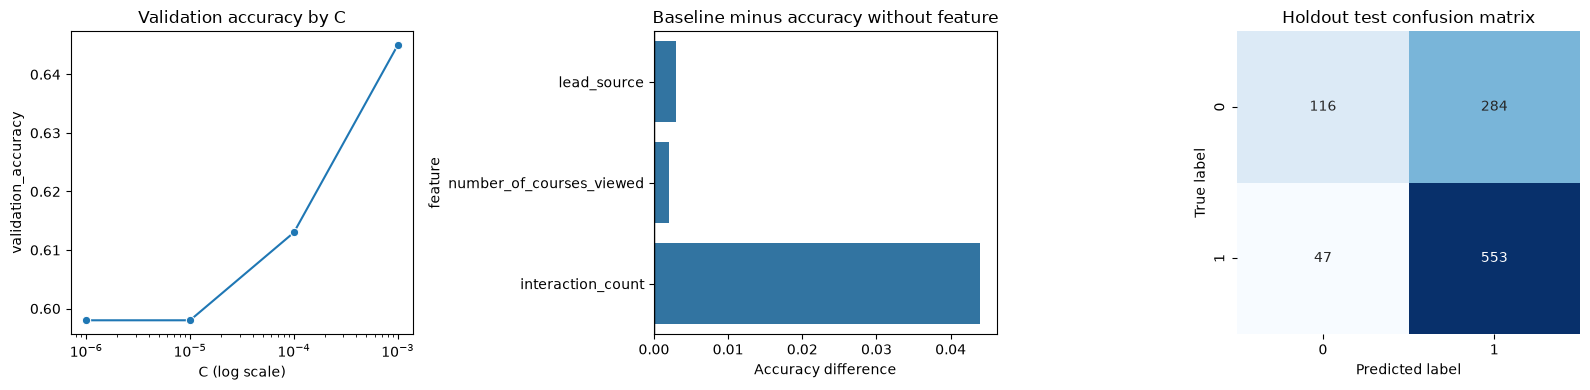

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.lineplot(
    data=regularization_table,
    x='C',
    y='validation_accuracy',
    marker='o',
    ax=axes[0],
)
axes[0].set_xscale('log')
axes[0].set_title('Validation accuracy by C')
axes[0].set_xlabel('C (log scale)')

sns.barplot(
    data=feature_elimination.reset_index(names='feature'),
    x='accuracy_difference',
    y='feature',
    ax=axes[1],
)
axes[1].axvline(0, color='black', linewidth=1)
axes[1].set_title('Baseline minus accuracy without feature')
axes[1].set_xlabel('Accuracy difference')

confusion = confusion_matrix(y_test, y_test_pred)
sns.heatmap(confusion, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[2])
axes[2].set_title('Holdout test confusion matrix')
axes[2].set_xlabel('Predicted label')
axes[2].set_ylabel('True label')

plt.tight_layout()
plt.show()

## 8. Save the model and results

Run this final cell to save the selected pipeline and a compact JSON report under `artifacts/`.

In [21]:
output_dir = Path('artifacts')
output_dir.mkdir(exist_ok=True)
model_path = output_dir / 'homework_03_logistic_regression.joblib'
results_path = output_dir / 'homework_03_results.json'

dump(best_model, model_path)
results = {
    'q1_industry_mode': str(industry_mode),
    'q2_candidate_correlations': {
        pair: float(value) for pair, value in pair_correlations.items()
    },
    'q3_mutual_information': {
        feature: float(value) for feature, value in mutual_information.items()
    },
    'q4_validation_accuracy': round(float(baseline_accuracy), 2),
    'q5_feature_elimination': {
        feature: {
            'accuracy_without_feature': float(row['accuracy_without_feature']),
            'accuracy_difference': float(row['accuracy_difference']),
        }
        for feature, row in feature_elimination.iterrows()
    },
    'q6_validation_accuracy_by_C': [
        {
            'C': result['C'],
            'accuracy': float(result['validation_accuracy']),
            'rounded_accuracy': result['rounded_accuracy'],
        }
        for result in regularization_results
    ],
    'q6_best_C': float(best_C),
    'holdout_test_accuracy': float(test_accuracy),
}
results_path.write_text(json.dumps(results, indent=2), encoding='utf-8')
print(f'Saved model: {model_path.resolve()}')
print(f'Saved results: {results_path.resolve()}')

Saved model: C:\Users\yanji\Projects\machine-learning-zoomcamp\cohorts\2026\homework\03-classification\artifacts\homework_03_logistic_regression.joblib
Saved results: C:\Users\yanji\Projects\machine-learning-zoomcamp\cohorts\2026\homework\03-classification\artifacts\homework_03_results.json
